<a href="https://colab.research.google.com/github/abdelrahmanessam-7-1/Linear-SVM/blob/main/Linear_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

In [ ]:
class LinearSVM_SMO:
    def __init__(self, C=1.0, tol=1e-3, eps=1e-8, max_iter=2000, seed=0):
        self.C = C
        self.tol = tol
        self.eps = eps
        self.max_iter = max_iter
        self.seed = seed

    def _all_errors(self):
        return (self.alpha * self.y) @ self.K + self.b - self.y

    def _err(self, i):
        return (self.alpha * self.y) @ self.K[:, i] + self.b - self.y[i]

    def _is_free(self):
        return (self.alpha > self.eps) & (self.alpha < self.C - self.eps)

    def _take_step(self, i1, i2):
        if i1 == i2:
            return 0
        a1, a2 = self.alpha[i1], self.alpha[i2]
        y1, y2 = self.y[i1], self.y[i2]
        E1, E2 = self._err(i1), self._err(i2)
        s = y1 * y2

        if y1 != y2:
            L, H = max(0.0, a2 - a1), min(self.C, self.C + a2 - a1)
        else:
            L, H = max(0.0, a1 + a2 - self.C), min(self.C, a1 + a2)
        if L >= H:
            return 0

        K11, K22, K12 = self.K[i1, i1], self.K[i2, i2], self.K[i1, i2]
        eta = K11 + K22 - 2.0 * K12
        if eta <= self.eps:
            return 0

        a2_new = a2 + y2 * (E1 - E2) / eta
        a2_new = min(max(a2_new, L), H)
        if abs(a2_new - a2) < self.eps * (a2_new + a2 + self.eps):
            return 0

        a1_new = a1 + s * (a2 - a2_new)

        b1 = self.b - E1 - y1 * (a1_new - a1) * K11 - y2 * (a2_new - a2) * K12
        b2 = self.b - E2 - y1 * (a1_new - a1) * K12 - y2 * (a2_new - a2) * K22
        if self.eps < a1_new < self.C - self.eps:
            self.b = b1
        elif self.eps < a2_new < self.C - self.eps:
            self.b = b2
        else:
            self.b = 0.5 * (b1 + b2)

        a1_new = 0.0 if a1_new < self.eps else (self.C if a1_new > self.C - self.eps else a1_new)
        a2_new = 0.0 if a2_new < self.eps else (self.C if a2_new > self.C - self.eps else a2_new)
        self.alpha[i1], self.alpha[i2] = a1_new, a2_new
        return 1

    def _examine(self, i2):
        y2, a2 = self.y[i2], self.alpha[i2]
        E2 = self._err(i2)
        r2 = E2 * y2
        if (r2 < -self.tol and a2 < self.C) or (r2 > self.tol and a2 > 0):
            free_idx = np.where(self._is_free())[0]
            if len(free_idx) > 1:
                errs = self._all_errors()
                i1 = free_idx[np.argmax(np.abs(errs[free_idx] - E2))]
                if self._take_step(i1, i2):
                    return 1
            for i1 in self.rng.permutation(free_idx):
                if self._take_step(i1, i2):
                    return 1
            for i1 in self.rng.permutation(len(self.y)):
                if self._take_step(i1, i2):
                    return 1
        return 0

    def fit(self, X, y):
        self.X = np.asarray(X, dtype=float)
        self.y = np.asarray(y, dtype=float)
        n = len(self.y)
        self.alpha = np.zeros(n)
        self.b = 0.0
        self.K = self.X @ self.X.T
        self.rng = np.random.default_rng(self.seed)

        num_changed, examine_all, it = 0, True, 0
        while (num_changed > 0 or examine_all) and it < self.max_iter:
            num_changed = 0
            if examine_all:
                for i in range(n):
                    num_changed += self._examine(i)
            else:
                for i in np.where(self._is_free())[0]:
                    num_changed += self._examine(i)
            if examine_all:
                examine_all = False
            elif num_changed == 0:
                examine_all = True
            it += 1
        self.n_iter = it

        self.sv_mask = self.alpha > 1e-5
        self.sv_idx = np.where(self.sv_mask)[0]
        self.w = (self.alpha * self.y) @ self.X

        free = (self.alpha > 1e-5) & (self.alpha < self.C - 1e-5)
        use = free if free.any() else self.sv_mask
        self.b_final = float(np.mean(self.y[use] - self.X[use] @ self.w))

        self.w_norm = float(np.linalg.norm(self.w))
        self.margin = 2.0 / self.w_norm
        self.n_free = int(free.sum())
        return self

    def decision_function(self, X):
        return np.asarray(X) @ self.w + self.b_final

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

In [ ]:
def make_separable(n_per_class=25, gap=1.5, angle_deg=35, spread=0.9, seed=0):
    rng = np.random.default_rng(seed)
    t = np.deg2rad(angle_deg)
    u = np.array([np.cos(t), np.sin(t)])
    pts, labels = [], []
    for s in (+1, -1):
        center = s * (gap / 2 + 1.3) * u
        got = 0
        while got < n_per_class:
            p = center + rng.normal(0, spread, size=2)
            if s * (u @ p) >= gap / 2:
                pts.append(p); labels.append(s); got += 1
    return np.array(pts), np.array(labels)

def make_overlapping(n_per_class=40, sep=1.5, spread=1.1, angle_deg=35, seed=3):
    rng = np.random.default_rng(seed)
    t = np.deg2rad(angle_deg)
    u = np.array([np.cos(t), np.sin(t)])
    Xp = sep * u + rng.normal(0, spread, size=(n_per_class, 2))
    Xn = -sep * u + rng.normal(0, spread, size=(n_per_class, 2))
    X = np.vstack([Xp, Xn])
    y = np.array([+1] * n_per_class + [-1] * n_per_class)
    return X, y

In [ ]:
def plot_svm(ax, m, title):
    X, y, w, b = m.X, m.y, m.w, m.b_final
    pad = 1.0
    xlim = (X[:, 0].min() - pad, X[:, 0].max() + pad)
    ylim = (X[:, 1].min() - pad, X[:, 1].max() + pad)

    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:blue", marker="o", s=45, label="Class +1", zorder=3)
    ax.scatter(X[y == -1, 0], X[y == -1, 1], c="tab:red", marker="s", s=45, label="Class -1", zorder=3)

    ax.scatter(X[m.sv_mask, 0], X[m.sv_mask, 1], s=230, facecolors="none",
               edgecolors="black", linewidths=1.8, label=f"Support vectors ({len(m.sv_idx)})", zorder=4)

    for c, style, lab, col in [(0, "-", "Decision boundary (w·x+b=0)", "black"),
                               (+1, "--", "Margin +1", "tab:blue"),
                               (-1, "--", "Margin -1", "tab:red")]:
        x1 = np.array(xlim)
        if abs(w[1]) > 1e-9:
            x2 = (c - b - w[0] * x1) / w[1]
            ax.plot(x1, x2, style, color=col, lw=1.8 if c == 0 else 1.3, label=lab)
        else:
            ax.axvline((c - b) / w[0], ls=style, color=col, label=lab)

    centre = X.mean(axis=0)
    p0 = centre - ((w @ centre + b) / (w @ w)) * w
    arrow = w / m.w_norm * (1.0 / m.w_norm)
    ax.annotate("", xy=p0 + arrow, xytext=p0,
                arrowprops=dict(arrowstyle="-|>", color="green", lw=2.5), zorder=5)
    ax.text(*(p0 + arrow * 1.05), f"w = [{w[0]:.2f}, {w[1]:.2f}]", color="green",
            fontsize=9, fontweight="bold", zorder=6)

    stats = (f"||w|| = {m.w_norm:.4f}\nb = {b:.4f}\n"
             f"margin = 2/||w|| = {m.margin:.4f}\n#SV = {len(m.sv_idx)}  (C = {m.C:g})")
    ax.text(0.02, 0.02, stats, transform=ax.transAxes, fontsize=9, va="bottom",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.9, edgecolor="gray"), zorder=7)

    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.legend(loc="upper left", fontsize=8)

def print_summary(name, m):
    f = m.y * m.decision_function(m.X)
    print("=" * 70)
    print(f"{name}")
    print("=" * 70)
    print(f"C = {m.C:g} | SMO sweeps: {m.n_iter} | samples: {len(m.y)}")
    print(f"Constraint check  sum(alpha_i*y_i) = {np.sum(m.alpha * m.y):+.2e}   (should be ~0)")
    print(f"Alpha range check: min = {m.alpha.min():.2e}, max = {m.alpha.max():.4f}  (must stay in [0, C])")
    print(f"\nSupport vectors found (alpha > 1e-5): {len(m.sv_idx)}  ({m.n_free} free, {len(m.sv_idx) - m.n_free} at alpha = C)")
    print(f"{'idx':>4} {'y':>3} {'x1':>9} {'x2':>9} {'alpha':>10}")
    show = 12
    for i in m.sv_idx[:show]:
        print(f"{i:>4} {int(m.y[i]):>3} {m.X[i,0]:>9.4f} {m.X[i,1]:>9.4f} {m.alpha[i]:>10.5f}")
    if len(m.sv_idx) > show:
        print(f"... plus {len(m.sv_idx) - show} more (mostly alpha = C)")
    print(f"\nw = sum(alpha_i y_i x_i) = [{m.w[0]:.5f}, {m.w[1]:.5f}]")
    print(f"b = mean(y_k - w.x_k) over free SVs = {m.b_final:.5f}")
    print(f"||w|| = {m.w_norm:.5f}")
    print(f"Margin width 2/||w|| = {m.margin:.5f}")
    print(f"Training accuracy = {np.mean(m.predict(m.X) == m.y) * 100:.1f}%  | "
          f"misclassified = {int(np.sum(f < 0))} | inside margin (y*f<1) = {int(np.sum(f < 1 - 1e-3))}\n")

results = {}

SCENARIO 1: separable data, hard margin (C = 10000)
C = 10000 | SMO sweeps: 7 | samples: 50
Constraint check  sum(alpha_i*y_i) = +0.00e+00   (should be ~0)
Alpha range check: min = 0.00e+00, max = 0.5900  (must stay in [0, C])

Support vectors found (alpha > 1e-5): 3  (3 free, 0 at alpha = C)
 idx   y        x1        x2      alpha
  17   1    1.2167   -0.3074    0.01981
  19   1    0.5746    0.5609    0.57015
  41  -1   -0.8839   -0.5640    0.58996

w = sum(alpha_i y_i x_i) = [0.87317, 0.64649]
b = mean(y_k - w.x_k) over free SVs = 0.13614
||w|| = 1.08645
Margin width 2/||w|| = 1.84085
Training accuracy = 100.0%  | misclassified = 0 | inside margin (y*f<1) = 0



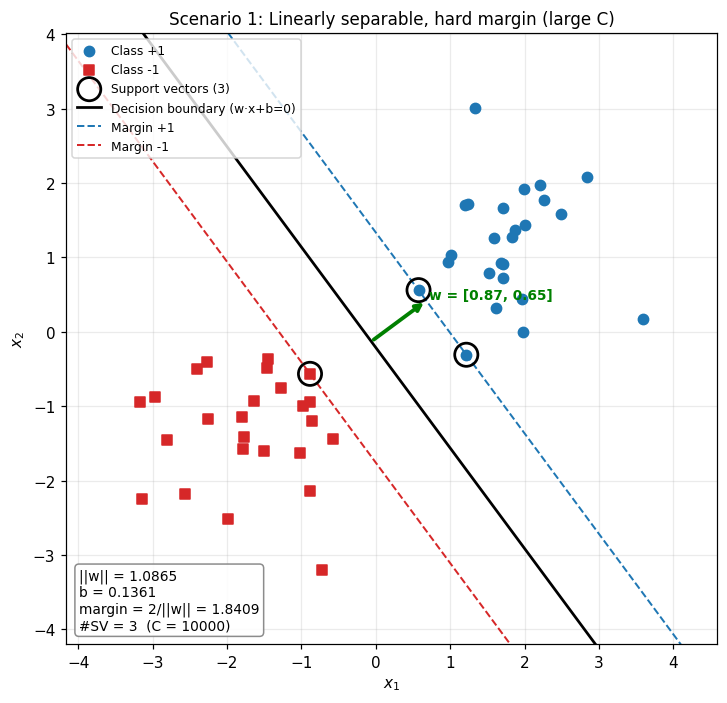

In [ ]:
X1, y1 = make_separable(n_per_class=25, gap=1.5, seed=1)
m1 = LinearSVM_SMO(C=1e4).fit(X1, y1)
results["S1 Hard margin"] = m1

print_summary("SCENARIO 1: separable data, hard margin (C = 10000)", m1)

fig, ax = plt.subplots(figsize=(7, 6.5))
plot_svm(ax, m1, "Scenario 1: Linearly separable, hard margin (large C)")
plt.tight_layout(); plt.show()

SCENARIO 2a: NARROW gap (true gap = 0.5)
C = 10000 | SMO sweeps: 7 | samples: 50
Constraint check  sum(alpha_i*y_i) = +2.78e-17   (should be ~0)
Alpha range check: min = 0.00e+00, max = 2.2549  (must stay in [0, C])

Support vectors found (alpha > 1e-5): 3  (3 free, 0 at alpha = C)
 idx   y        x1        x2      alpha
  19   1    0.5817   -0.0821    2.25485
  32  -1    0.0894   -0.8971    2.01082
  48  -1   -0.9086   -0.0715    0.24404

w = sum(alpha_i y_i x_i) = [1.35351, 1.63621]
b = mean(y_k - w.x_k) over free SVs = 0.34690
||w|| = 2.12348
Margin width 2/||w|| = 0.94185
Training accuracy = 100.0%  | misclassified = 0 | inside margin (y*f<1) = 0

SCENARIO 2b: WIDE gap (true gap = 3.0)
C = 10000 | SMO sweeps: 10 | samples: 50
Constraint check  sum(alpha_i*y_i) = -2.78e-17   (should be ~0)
Alpha range check: min = 0.00e+00, max = 0.1738  (must stay in [0, C])

Support vectors found (alpha > 1e-5): 2  (2 free, 0 at alpha = C)
 idx   y        x1        x2      alpha
  19   1    1.6056

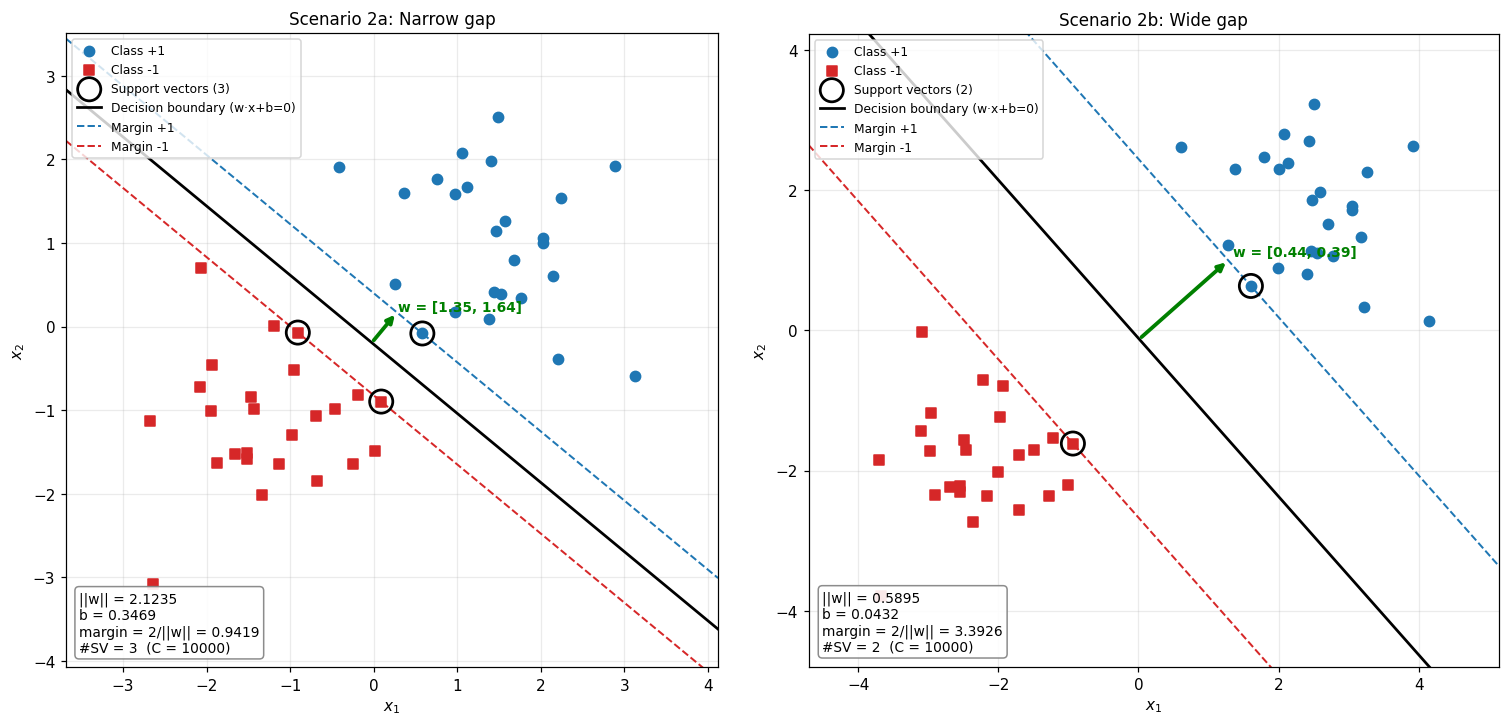

In [ ]:
Xn, yn = make_separable(n_per_class=25, gap=0.5, seed=2)
Xw, yw = make_separable(n_per_class=25, gap=3.0, seed=2)
mn = LinearSVM_SMO(C=1e4).fit(Xn, yn)
mw = LinearSVM_SMO(C=1e4).fit(Xw, yw)
results["S2 Narrow gap"] = mn
results["S2 Wide gap"] = mw

print_summary("SCENARIO 2a: NARROW gap (true gap = 0.5)", mn)
print_summary("SCENARIO 2b: WIDE gap (true gap = 3.0)", mw)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
plot_svm(axes[0], mn, "Scenario 2a: Narrow gap")
plot_svm(axes[1], mw, "Scenario 2b: Wide gap")
plt.tight_layout(); plt.show()

SCENARIO 3a: overlapping data, LOW C = 0.05
C = 0.05 | SMO sweeps: 34 | samples: 80
Constraint check  sum(alpha_i*y_i) = +1.39e-17   (should be ~0)
Alpha range check: min = 0.00e+00, max = 0.0500  (must stay in [0, C])

Support vectors found (alpha > 1e-5): 39  (3 free, 36 at alpha = C)
 idx   y        x1        x2      alpha
   0   1    3.4737   -1.9509    0.01055
   2   1    0.7308    0.6232    0.05000
   3   1   -0.9933    0.6052    0.05000
   5   1    1.4771    0.4725    0.03393
   6   1    0.9193    0.1255    0.05000
   7   1    0.0681    0.4305    0.05000
  15   1    0.2536    0.5395    0.05000
  18   1   -1.8823    1.9838    0.05000
  19   1    0.1731   -0.9751    0.05000
  21   1    0.7395   -0.3237    0.05000
  25   1    1.0027   -0.1581    0.05000
  27   1    0.9924   -0.0007    0.05000
... plus 27 more (mostly alpha = C)

w = sum(alpha_i y_i x_i) = [0.55226, 0.45502]
b = mean(y_k - w.x_k) over free SVs = -0.03091
||w|| = 0.71557
Margin width 2/||w|| = 2.79499
Training accura

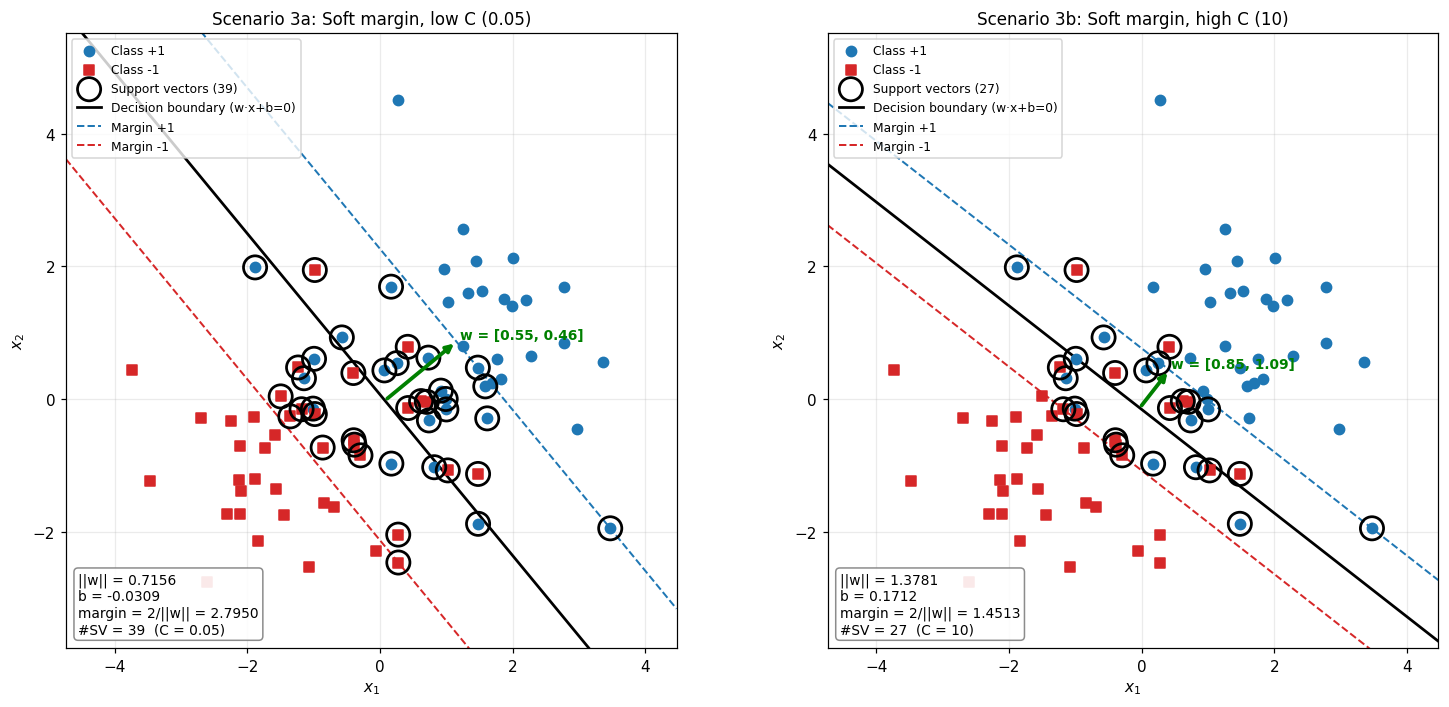

In [ ]:
Xo, yo = make_overlapping(n_per_class=40, seed=3)
m_low = LinearSVM_SMO(C=0.05).fit(Xo, yo)
m_high = LinearSVM_SMO(C=10).fit(Xo, yo)
results["S3 Low C"] = m_low
results["S3 High C"] = m_high

print_summary("SCENARIO 3a: overlapping data, LOW C = 0.05", m_low)
print_summary("SCENARIO 3b: overlapping data, HIGH C = 10", m_high)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
plot_svm(axes[0], m_low, "Scenario 3a: Soft margin, low C (0.05)")
plot_svm(axes[1], m_high, "Scenario 3b: Soft margin, high C (10)")
plt.tight_layout(); plt.show()

In [ ]:
def stats(m):
    f = m.y * m.decision_function(m.X)
    return dict(sv=len(m.sv_idx), margin=m.margin, wn=m.w_norm, b=m.b_final,
                acc=np.mean(m.predict(m.X) == m.y) * 100,
                mis=int(np.sum(f < 0)), inside=int(np.sum(f < 1 - 1e-3)), C=m.C)

S = {k: stats(v) for k, v in results.items()}

print("SUMMARY TABLE")
print(f"{'Scenario':<16}{'C':>8}{'||w||':>9}{'b':>9}{'Margin':>9}{'#SV':>6}{'Acc %':>8}{'Misclf':>8}{'In-margin':>11}")
for k, s in S.items():
    print(f"{k:<16}{s['C']:>8g}{s['wn']:>9.3f}{s['b']:>9.3f}{s['margin']:>9.3f}{s['sv']:>6}{s['acc']:>8.1f}{s['mis']:>8}{s['inside']:>11}")

s1, sn, sw = S["S1 Hard margin"], S["S2 Narrow gap"], S["S2 Wide gap"]
lo, hi = S["S3 Low C"], S["S3 High C"]
ratio = sw["margin"] / sn["margin"]
wide_word = "wider" if lo["margin"] > hi["margin"] else "narrower"

print("\n" + "=" * 70)
print("SLIDE-READY TEXT")
print("=" * 70)

print(f"""
SLIDE 1: How the model works
- Solve the dual: maximize sum(a) - 0.5*sum(a_i a_j y_i y_j x_i.x_j)
- Constraints: sum(a_i y_i) = 0 and 0 <= a_i <= C
- Solved from scratch with SMO (pairs of alphas updated analytically)
- Recover w = sum(a_i y_i x_i), b = y_k - w.x_k, margin = 2/||w||
- Only points with alpha > 0 (support vectors) shape the boundary

SLIDE 2: Scenario 1, hard margin (separable data)
- Margin width = {s1['margin']:.3f}, ||w|| = {s1['wn']:.3f}, b = {s1['b']:.3f}
- Only {s1['sv']} of 50 points are support vectors
- Training accuracy = {s1['acc']:.0f}%, zero points inside the margin
- Takeaway: the boundary is decided by a handful of boundary points, not the whole dataset

SLIDE 3: Scenario 2, narrow vs wide gap
- Narrow gap: margin = {sn['margin']:.3f}, ||w|| = {sn['wn']:.3f}, #SV = {sn['sv']}
- Wide gap:   margin = {sw['margin']:.3f}, ||w|| = {sw['wn']:.3f}, #SV = {sw['sv']}
- Wider data gap gives a {ratio:.1f}x larger margin
- Margin and ||w|| are inversely related: bigger margin = smaller ||w||
- Takeaway: a wide margin means more robust classification and usually better generalization

SLIDE 4: Scenario 3, soft margin, effect of C
- Low C ({lo['C']:g}):  margin = {lo['margin']:.3f}, #SV = {lo['sv']}, accuracy = {lo['acc']:.1f}%, inside-margin points = {lo['inside']}
- High C ({hi['C']:g}): margin = {hi['margin']:.3f}, #SV = {hi['sv']}, accuracy = {hi['acc']:.1f}%, inside-margin points = {hi['inside']}
- Low C gives a {wide_word} margin than high C, with more tolerance for violations
- High C punishes slack heavily and the boundary chases individual points
- Takeaway: C is the bias-variance dial (low C = simpler, smoother; high C = fits training data harder)

SLIDE 5: Key conclusions
- Margin width = 2/||w||, so maximizing margin means minimizing ||w||
- Support vector count: {s1['sv']} (hard margin) vs {lo['sv']} (low C) vs {hi['sv']} (high C)
- Hard margin only works when the data is truly separable; otherwise use soft margin
- Choose C by cross-validation: too high risks overfitting noise, too low risks underfitting
""")

SUMMARY TABLE
Scenario               C    ||w||        b   Margin   #SV   Acc %  Misclf  In-margin
S1 Hard margin     10000    1.086    0.136    1.841     3   100.0       0          0
S2 Narrow gap      10000    2.123    0.347    0.942     3   100.0       0          0
S2 Wide gap        10000    0.590    0.043    3.393     2   100.0       0          0
S3 Low C            0.05    0.716   -0.031    2.795    39    82.5      14         36
S3 High C             10    1.378    0.171    1.451    27    83.8      13         24

SLIDE-READY TEXT

SLIDE 1: How the model works
- Solve the dual: maximize sum(a) - 0.5*sum(a_i a_j y_i y_j x_i.x_j)
- Constraints: sum(a_i y_i) = 0 and 0 <= a_i <= C
- Solved from scratch with SMO (pairs of alphas updated analytically)
- Recover w = sum(a_i y_i x_i), b = y_k - w.x_k, margin = 2/||w||
- Only points with alpha > 0 (support vectors) shape the boundary

SLIDE 2: Scenario 1, hard margin (separable data)
- Margin width = 1.841, ||w|| = 1.086, b = 0.136
- Only 